<a href="https://colab.research.google.com/github/pusalaspreetham-code/amazon-review-analyzer/blob/main/data_prepocessing/sentiment_preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Import libraries and load the dataset

In [ ]:
import pandas as pd
import numpy as np

# Load preprocessed dataset
df = pd.read_csv("/content/amazon_reviews_cleaned.csv")

# Display dataset information
print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (11462, 20)


,review_id,product_id,product_name,category,product_url,price,original_price,product_rating,total_product_reviews,five_star_review_count,four_star_review_count,three_star_review_count,two_star_review_count,one_star_review_count,review_title,review_text,review_rating,helpful_votes,review_age,discount_percentage
0,RKSVOZF894JFW,B00791CQ5K,"Palmolive Aroma Morning Tonic Body Wash, 250ml...",Beauty > Bath & Body > Cleansers > Body Wash Gels,https://amzn.in/d/0iydsUco,99.0,259.0,4.4,8792,465,214,91,29,76,Best shower gel,Love this shower gel feels fresh in every shower,5.0,0,1 year ago,61.78
1,R1ZNY7WGCQTRY4,B00791CQ5K,"Palmolive Aroma Morning Tonic Body Wash, 250ml...",Beauty > Bath & Body > Cleansers > Body Wash Gels,https://amzn.in/d/0iydsUco,99.0,259.0,4.4,8792,465,214,91,29,76,Doubt its original as quality and scent not same,Quality deteriorated scent is almost negligibl...,2.0,2,3 years ago,61.78
2,RK2R8UNJ28858,B00791CQ5K,"Palmolive Aroma Morning Tonic Body Wash, 250ml...",Beauty > Bath & Body > Cleansers > Body Wash Gels,https://amzn.in/d/0iydsUco,99.0,259.0,4.4,8792,465,214,91,29,76,Average product,Soap remains on body even after thorough wash,3.0,1,3 years ago,61.78
3,R1PSRBJB5CR0XE,B00791CQ5K,"Palmolive Aroma Morning Tonic Body Wash, 250ml...",Beauty > Bath & Body > Cleansers > Body Wash Gels,https://amzn.in/d/0iydsUco,99.0,259.0,4.4,8792,465,214,91,29,76,Awesome fragrance,Fragrance is really nice and refreshing also e...,4.0,1,2 years ago,61.78
4,R3FK9S0MB6SRS4,B00791CQ5K,"Palmolive Aroma Morning Tonic Body Wash, 250ml...",Beauty > Bath & Body > Cleansers > Body Wash Gels,https://amzn.in/d/0iydsUco,99.0,259.0,4.4,8792,465,214,91,29,76,The nozzle was open so liquid soap leaked,The nozzle was not correctly and liquid soap w...,1.0,1,2 years ago,61.78


Check review text

In [ ]:
df["review_text"].head(5)

,review_text
0,Love this shower gel feels fresh in every shower
1,Quality deteriorated scent is almost negligibl...
2,Soap remains on body even after thorough wash
3,Fragrance is really nice and refreshing also e...
4,The nozzle was not correctly and liquid soap w...


Import of dataset that has sentiment column

In [ ]:
df1 = pd.read_csv("/content/EMNLP2023-MCD.csv")
print("Dataset Shape:", df1.shape)
df1.head()

Dataset Shape: (7890, 8)


,PageURL,Domain,ImageURL,Title,Review,Emotion,Sentiment,Complaint
0,https://www.amazon.in/Atomic-Habits-James-Clea...,Books,https://images-na.ssl-images-amazon.com/images...,Must read book | Measure your growth,"\n Before starting this book, write down some ...",happiness,positive,non-complaint
1,https://www.amazon.in/Atomic-Habits-James-Clea...,Books,https://images-na.ssl-images-amazon.com/images...,This is one of the best books I have read so far.,\n I follow James Clear email articles and thi...,happiness,positive,non-complaint
2,https://www.amazon.in/Atomic-Habits-James-Clea...,Books,https://images-na.ssl-images-amazon.com/images...,A great book on human behaviour,\n There are some books which are feel good bo...,happiness,positive,non-complaint
3,https://www.amazon.in/Atomic-Habits-James-Clea...,Books,https://images-na.ssl-images-amazon.com/images...,It’s an amazing amazing guide. A must read if ...,\n This book is about how one can build good h...,happiness,positive,non-complaint
4,https://www.amazon.in/Atomic-Habits-James-Clea...,Books,https://images-na.ssl-images-amazon.com/images...,Life Changing!!!,\n I got my book positive days ago and till no...,happiness,positive,non-complaint


Dataset info

In [ ]:
print("Dataset Columns:")
print(df1.columns.tolist())
df1.info()

Dataset Columns:
['PageURL', 'Domain', 'ImageURL', 'Title', 'Review', 'Emotion', 'Sentiment', 'Complaint']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7890 entries, 0 to 7889
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   PageURL    7890 non-null   object
 1   Domain     7890 non-null   object
 2   ImageURL   7782 non-null   object
 3   Title      7890 non-null   object
 4   Review     7877 non-null   object
 5   Emotion    7889 non-null   object
 6   Sentiment  7890 non-null   object
 7   Complaint  7890 non-null   object
dtypes: object(8)
memory usage: 493.3+ KB


Check unique values in each column

In [ ]:
for column in df.columns:
    print(f"\nColumn: {column}")
    print("Unique values:", df[column].nunique())
    print("Sample values:", df[column].dropna().unique()[:5])


Column: review_id
Unique values: 11398
Sample values: ['RKSVOZF894JFW' 'R1ZNY7WGCQTRY4' 'RK2R8UNJ28858' 'R1PSRBJB5CR0XE'
 'R3FK9S0MB6SRS4']

Column: product_id
Unique values: 149
Sample values: ['B00791CQ5K' 'B0GYRGV13D' 'B0CL7CMTXS' 'B0GV1L119H' 'B0DSFQZTVW']

Column: product_name
Unique values: 150
Sample values: ['Palmolive Aroma Morning Tonic Body Wash, 250ml Shower Gel Single Bottle, 100% Natural Citrus Essential Oil & Lemongrass Extracts for a Smooth Skin, Green'
 'Acer Smartchoice Aspire One, AMD Ryzen 3-7320U, 8GB LPDDR5 RAM/ 512GB SSD, 14.0"/35.56cm TN HD Display, Win 11 Home, Pure Silver, 1.48KG, A114-43, Thin and Light Laptop'
 'Lenovo V15 G4 AMD Athlon Silver 7120U Laptop'
 'Dell 15 (Previously Inspiron) Laptop, 14th Gen Intel Core i3/Core 3 100U Processor, 16GB DDR4, 512 SSD, Intel UHD Graphics, 15.6" FHD 120Hz IPS AG 250 nit Display, Win 11 + Office 2024, Black, 1.63Kg'
 'Dell 15 SmartChoice (Previously Inspiron), Intel 13th Gen Core i5-1334U, 16GB, 1TB SSD, FHD,15.6"/39

Sentiment distribution

In [ ]:
print("Sentiment Distribution:")
print(df1["Sentiment"].value_counts())

print("\nSentiment Percentages:")
print((df1["Sentiment"].value_counts(normalize=True) * 100).round(2))

Sentiment Distribution:
Sentiment
positive    4160
negative    2563
neutral     1167
Name: count, dtype: int64

Sentiment Percentages:
Sentiment
positive    52.72
negative    32.48
neutral     14.79
Name: proportion, dtype: float64


Missing values and sample reviews

In [ ]:
print("Missing Values:")
print(df1.isnull().sum())

for sentiment in df1["Sentiment"].unique():
    print("\n", sentiment.upper())

    display(
        df1[df1["Sentiment"] == sentiment][
            ["Title", "Review", "Sentiment"]
        ].head(3)
    )

Missing Values:
PageURL        0
Domain         0
ImageURL     108
Title          0
Review        13
Emotion        1
Sentiment      0
Complaint      0
dtype: int64

 POSITIVE


,Title,Review,Sentiment
0,Must read book | Measure your growth,"\n Before starting this book, write down some ...",positive
1,This is one of the best books I have read so far.,\n I follow James Clear email articles and thi...,positive
2,A great book on human behaviour,\n There are some books which are feel good bo...,positive



 NEUTRAL


,Title,Review,Sentiment
4160,Honest review,\n A most practical book on human physiology o...,neutral
4161,Excellent book.,\n It's an excellent book for people who wanna...,neutral
4162,Nice Book but Receive Duplicate Copy By Seller...,\n Book Was awesome a must read book but not s...,neutral



 NEGATIVE


,Title,Review,Sentiment
5327,"Pirated copy, Highly disappointed",\n The pages used in the book are of so low qu...,negative
5328,Pirated Copy!,\n Extremely disappointing by amazon.. The pic...,negative
5329,"Worst packaging, no problem about content",\n The book is very good. But the packaging is...,negative


Removing missing values and adding combing both title and review

In [ ]:
df1=df1.dropna(subset=['Review'])
df1["review_text"] = (
    df1["Title"].fillna("").astype(str) + " " +
    df1["Review"].astype(str)
).str.strip()

print(df1[["Title", "Review", "review_text", "Sentiment"]].head())

empty_reviews = df1["review_text"].str.strip().eq("")

print("Empty reviews:", empty_reviews.sum())

df1 = df1[~empty_reviews].copy()

print("Final Dataset Shape:", df1.shape)

                                               Title  \
0               Must read book | Measure your growth   
1  This is one of the best books I have read so far.   
2                    A great book on human behaviour   
3  It’s an amazing amazing guide. A must read if ...   
4                                   Life Changing!!!   

                                              Review  \
0  \n Before starting this book, write down some ...   
1  \n I follow James Clear email articles and thi...   
2  \n There are some books which are feel good bo...   
3  \n This book is about how one can build good h...   
4  \n I got my book positive days ago and till no...   

                                         review_text Sentiment  
0  Must read book | Measure your growth \n Before...  positive  
1  This is one of the best books I have read so f...  positive  
2  A great book on human behaviour \n There are s...  positive  
3  It’s an amazing amazing guide. A must read if ...  positive  
4

EDA

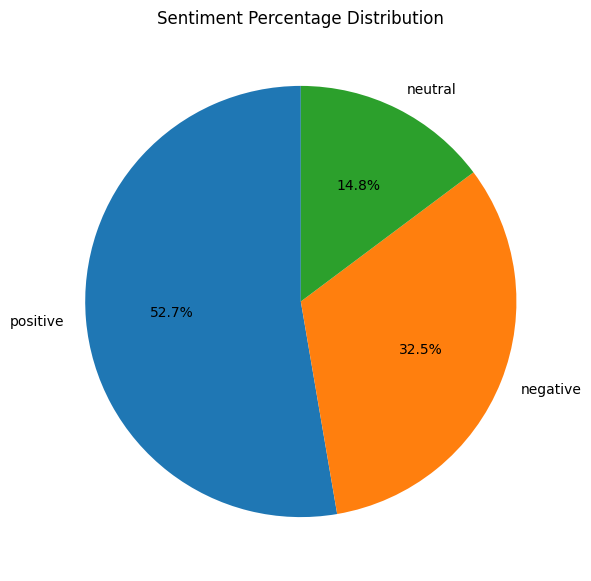

In [ ]:
sentiment_percent = (
    df1["Sentiment"].value_counts(normalize=True) * 100
)

plt.figure(figsize=(7, 7))

plt.pie(
    sentiment_percent,
    labels=sentiment_percent.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Sentiment Percentage Distribution")
plt.show()

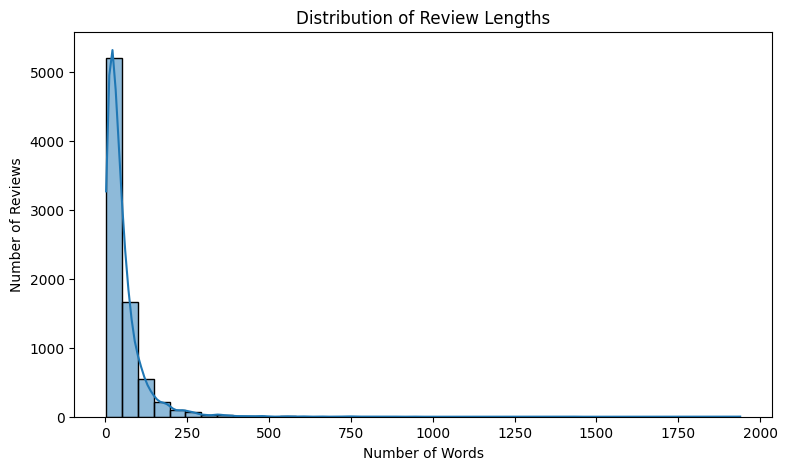

count    7877.000000
mean       53.623461
std        69.352566
min         3.000000
25%        17.000000
50%        35.000000
75%        65.000000
max      1939.000000
Name: review_length, dtype: float64


In [ ]:
df1["review_length"] = df1["review_text"].apply(
    lambda text: len(text.split())
)

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df1,
    x="review_length",
    bins=40,
    kde=True
)

plt.title("Distribution of Review Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")
plt.show()

print(df1["review_length"].describe())

Train-Test Split

In [ ]:
from sklearn.model_selection import train_test_split

X = df1["review_text"]
y = df1["Sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining sentiment distribution:")
print(y_train.value_counts())

print("\nTesting sentiment distribution:")
print(y_test.value_counts())

Training samples: 6301
Testing samples: 1576

Training sentiment distribution:
Sentiment
positive    3321
negative    2049
neutral      931
Name: count, dtype: int64

Testing sentiment distribution:
Sentiment
positive    830
negative    513
neutral     233
Name: count, dtype: int64


Converting review text using TF-IDF

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF Shape:", X_train_tfidf.shape)
print("Testing TF-IDF Shape:", X_test_tfidf.shape)

Training TF-IDF Shape: (6301, 30000)
Testing TF-IDF Shape: (1576, 30000)
